✅ Data loaded successfully!
Training shape: (5045, 45)
Testing shape: (2163, 45)
Detected target column: Severity
🕓 Datetime columns converted successfully!
🔢 All categorical columns encoded!
🌳 Decision Tree trained successfully!


/var/folders/_b/djt2169j41x0cnzlfx4l6hn40000gn/T/ipykernel_10098/988429851.py:51: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_copy[col] = pd.to_datetime(df_copy[col], errors='coerce')
/var/folders/_b/djt2169j41x0cnzlfx4l6hn40000gn/T/ipykernel_10098/988429851.py:51: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_copy[col] = pd.to_datetime(df_copy[col], errors='coerce')


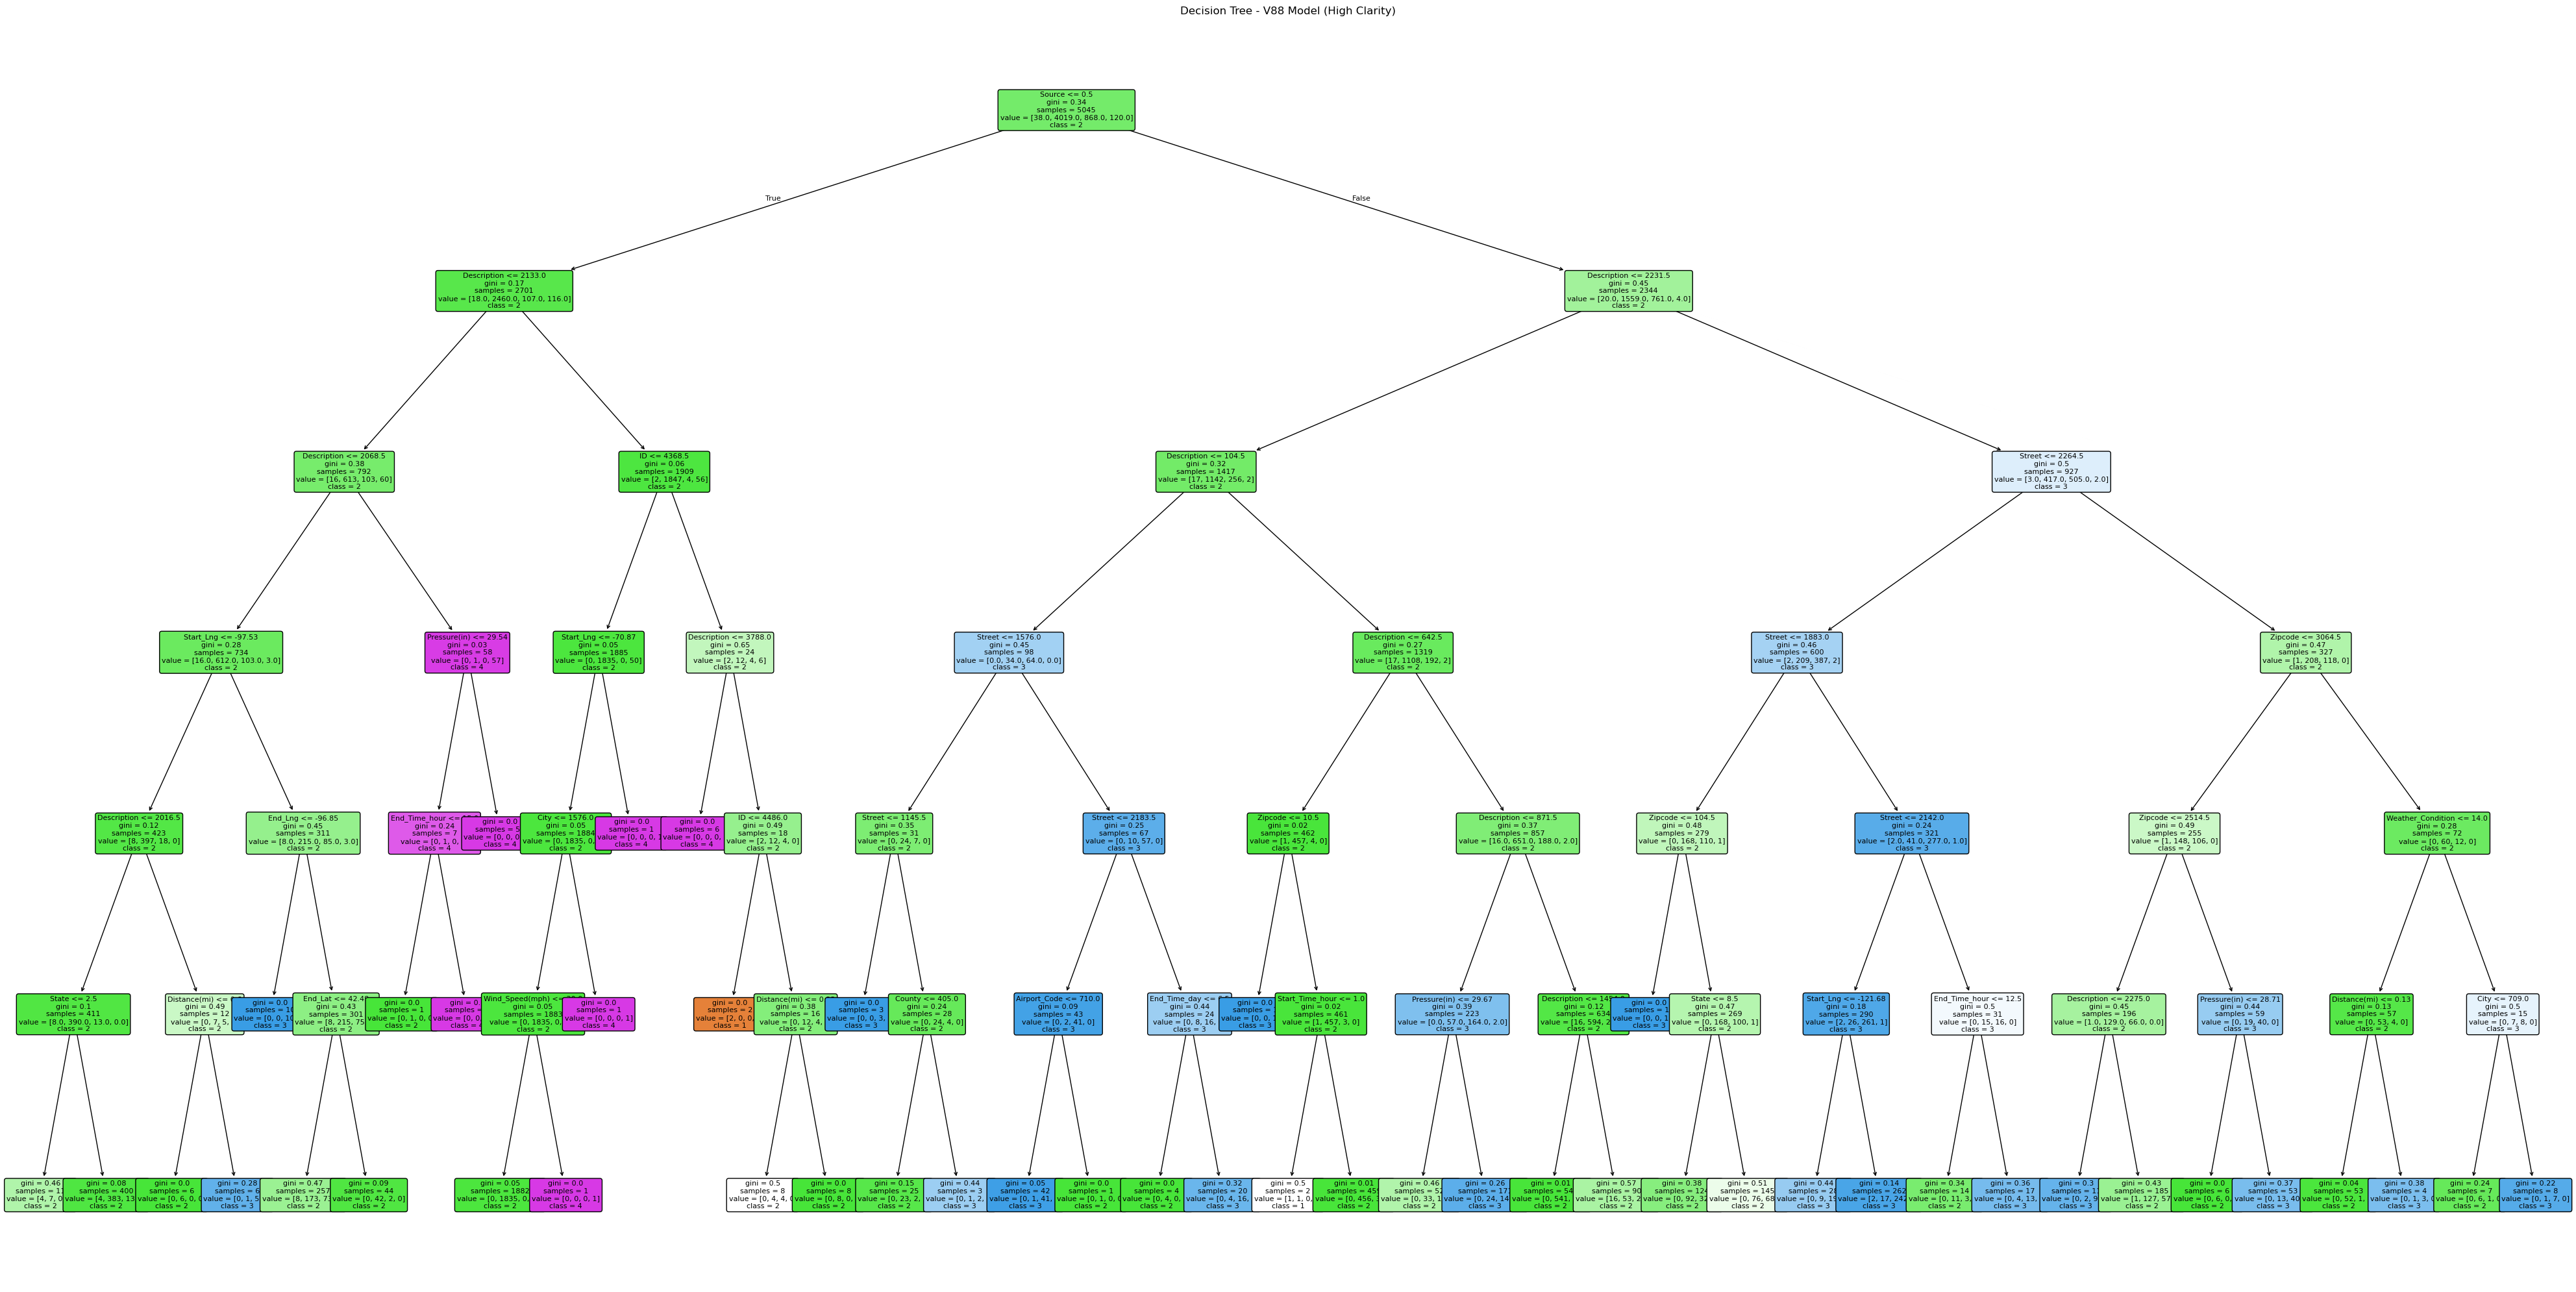

✅ Train/Test feature columns now fully aligned!

📊 Model Evaluation:
Accuracy: 0.761

Confusion Matrix:
 [[   0   28    0    0]
 [   1 1615   52   48]
 [   2  340   32    0]
 [   0   44    1    0]]

Classification Report:
               precision    recall  f1-score   support

           1       0.00      0.00      0.00        28
           2       0.80      0.94      0.86      1716
           3       0.38      0.09      0.14       374
           4       0.00      0.00      0.00        45

    accuracy                           0.76      2163
   macro avg       0.29      0.26      0.25      2163
weighted avg       0.70      0.76      0.71      2163

💾 Results saved successfully to results.txt!


In [8]:
# ===========================================
# Decision Tree Classifier - Handle datetime columns
# ===========================================

import pandas as pd
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt

# -----------------------------
# 1. Load data
# -----------------------------
train_path = "train_transformed_data_V88.xlsx"
test_path = "test_transformed_data_V88.xlsx"

train_df = pd.read_excel(train_path)
test_df = pd.read_excel(test_path)

print("✅ Data loaded successfully!")
print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

# -----------------------------
# 2. Detect target column
# -----------------------------
target_col = None
for col in train_df.columns:
    if col.lower() in ["severity", "target", "label", "class"]:
        target_col = col
        break
if not target_col:
    raise ValueError("❌ Target column not found!")

X_train = train_df.drop(columns=[target_col])
y_train = train_df[target_col]

X_test = test_df.drop(columns=[target_col], errors="ignore")
y_test = test_df[target_col] if target_col in test_df.columns else None

print(f"Detected target column: {target_col}")

# -----------------------------
# 3. Handle datetime columns
# -----------------------------
def process_datetime(df):
    df_copy = df.copy()
    for col in df_copy.columns:
        if pd.api.types.is_datetime64_any_dtype(df_copy[col]) or "time" in col.lower():
            try:
                df_copy[col] = pd.to_datetime(df_copy[col], errors='coerce')
                df_copy[col + "_hour"] = df_copy[col].dt.hour
                df_copy[col + "_day"] = df_copy[col].dt.day
                df_copy[col + "_month"] = df_copy[col].dt.month
                df_copy[col + "_weekday"] = df_copy[col].dt.weekday
                df_copy.drop(columns=[col], inplace=True)
            except:
                pass
    return df_copy

X_train = process_datetime(X_train)
X_test = process_datetime(X_test)
print("🕓 Datetime columns converted successfully!")

# -----------------------------
# 4. Encode non-numeric features
# -----------------------------
label_encoders = {}

def encode_dataframe(df):
    df_encoded = df.copy()
    for col in df_encoded.columns:
        if df_encoded[col].dtype == "object":
            le = LabelEncoder()
            df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))
            label_encoders[col] = le
    return df_encoded

X_train_enc = encode_dataframe(X_train)
X_test_enc = encode_dataframe(X_test)
print("🔢 All categorical columns encoded!")

# -----------------------------
# 5. Train Decision Tree
# -----------------------------
clf = DecisionTreeClassifier(
    criterion='gini',
    max_depth=6,
    random_state=42
)
clf.fit(X_train_enc, y_train)
print("🌳 Decision Tree trained successfully!")

# -----------------------------
# 6. Plot the tree
# -----------------------------
plt.figure(figsize=(40, 20))
plot_tree(
    clf,
    filled=True,
    feature_names=X_train_enc.columns,
    class_names=[str(c) for c in clf.classes_],
    rounded=True,
    fontsize=8,
    precision=2
)
plt.title("Decision Tree - V88 Model (High Clarity)")
plt.tight_layout()
plt.show()

# -----------------------------
# 7. Make sure train/test features match
# -----------------------------
missing_cols = set(X_train_enc.columns) - set(X_test_enc.columns)
for col in missing_cols:
    X_test_enc[col] = 0

X_test_enc = X_test_enc[X_train_enc.columns]
print("✅ Train/Test feature columns now fully aligned!")

# -----------------------------
# 8. Evaluate Model
# -----------------------------
if y_test is not None:
    y_pred = clf.predict(X_test_enc)
    acc = accuracy_score(y_test, y_pred)
    print("\n📊 Model Evaluation:")
    print("Accuracy:", round(acc, 3))
    print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print("\nClassification Report:\n", classification_report(y_test, y_pred))

    # -----------------------------
    # 9. Save results to TXT
    # -----------------------------
    with open("results.txt", "w") as f:
        f.write("✅ Model Evaluation Results\n")
        f.write("=========================\n\n")
        f.write(f"Accuracy: {acc:.3f}\n\n")
        f.write("Confusion Matrix:\n")
        f.write(str(confusion_matrix(y_test, y_pred)))
        f.write("\n\n")
        f.write("Classification Report:\n")
        f.write(classification_report(y_test, y_pred))
    print("💾 Results saved successfully to results.txt!")
